In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import numpy as np
import matplotlib.pyplot as plt

torch.manual_seed(42)

train_images = np.load('/content/train_images.npy').astype(np.float32) / 255.0
train_labels = np.load('/content/train_labels.npy').astype(np.int64)
test_images = np.load('/content/test_images.npy').astype(np.float32) / 255.0
test_labels = np.load('/content/test_labels.npy').astype(np.int64)

if len(train_images.shape) == 3:
    train_images = np.expand_dims(train_images, 1)
    test_images = np.expand_dims(test_images, 1)

train_dataset = TensorDataset(torch.tensor(train_images), torch.tensor(train_labels))
test_dataset = TensorDataset(torch.tensor(test_images), torch.tensor(test_labels))

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=1000, shuffle=False)

In [2]:
class BaselineCNN(nn.Module):
    def __init__(self):
        super(BaselineCNN, self).__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )
        self.fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.fc(self.conv(x))

In [3]:
model = BaselineCNN()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print("Training baseline CNN (2 epochs)...", end="")
model.train()
for epoch in range(2):
    for images, labels in train_loader:
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
print(" done.")

Training baseline CNN (2 epochs)... done.


In [4]:
def fgsm_attack(images, epsilon, data_grad):
    perturbed_image = images + epsilon * data_grad.sign()
    return torch.clamp(perturbed_image, 0, 1)

def pgd_attack(model, images, labels, epsilon, alpha, num_iter=10):
    perturbed_images = images.clone().detach()
    if epsilon == 0:
        return perturbed_images

    perturbed_images = perturbed_images + torch.empty_like(perturbed_images).uniform_(-epsilon, epsilon)
    perturbed_images = torch.clamp(perturbed_images, 0, 1)

    for _ in range(num_iter):
        perturbed_images.requires_grad = True
        outputs = model(perturbed_images)
        loss = criterion(outputs, labels)
        model.zero_grad()
        loss.backward()

        with torch.no_grad():
            adv_images = perturbed_images + alpha * perturbed_images.grad.sign()
            eta = torch.clamp(adv_images - images, min=-epsilon, max=epsilon)
            perturbed_images = torch.clamp(images + eta, min=0, max=1).detach()

    return perturbed_images

In [5]:
def evaluate_attack(model, device, test_loader, epsilon, attack_type):
    correct = 0
    total = 0
    model.eval()

    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        if attack_type == 'clean':
            outputs = model(images)
            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
        elif attack_type == 'fgsm':
            images.requires_grad = True
            outputs = model(images)
            loss = criterion(outputs, labels)
            model.zero_grad()
            loss.backward()
            data_grad = images.grad.data
            perturbed_images = fgsm_attack(images, epsilon, data_grad)
            outputs_adv = model(perturbed_images)
            _, preds = torch.max(outputs_adv, 1)
            correct += (preds == labels).sum().item()
        elif attack_type == 'pgd':
            alpha = epsilon / 4.0
            perturbed_images = pgd_attack(model, images, labels, epsilon, alpha)
            outputs_adv = model(perturbed_images)
            _, preds = torch.max(outputs_adv, 1)
            correct += (preds == labels).sum().item()
        total += labels.size(0)
    return (correct / total) * 100

In [6]:
device = torch.device("cpu")
epsilons = [0.00, 0.05, 0.10, 0.20, 0.30]
fgsm_accs = []
pgd_accs = []

for eps in epsilons:
    if eps == 0.0:
        acc = evaluate_attack(model, device, test_loader, 0.0, 'clean')
        fgsm_accs.append(acc)
        pgd_accs.append(acc)
    else:
        fgsm_accs.append(evaluate_attack(model, device, test_loader, eps, 'fgsm'))
        pgd_accs.append(evaluate_attack(model, device, test_loader, eps, 'pgd'))

clean_acc = fgsm_accs[0]
print(f"Clean test accuracy : {clean_acc:.1f} %")
print("\nEPSILON FGSM_ACC PGD_ACC")
print("-------------------------------")
for eps, f_acc, p_acc in zip(epsilons, fgsm_accs, pgd_accs):
    print(f"{eps:.2f}  {f_acc:.1f} %  {p_acc:.1f} %")
print("-------------------------------")

Clean test accuracy : 98.6 %

EPSILON FGSM_ACC PGD_ACC
-------------------------------
0.00  98.6 %  98.6 %
0.05  95.9 %  95.3 %
0.10  88.6 %  82.3 %
0.20  49.8 %  7.7 %
0.30  12.1 %  0.0 %
-------------------------------


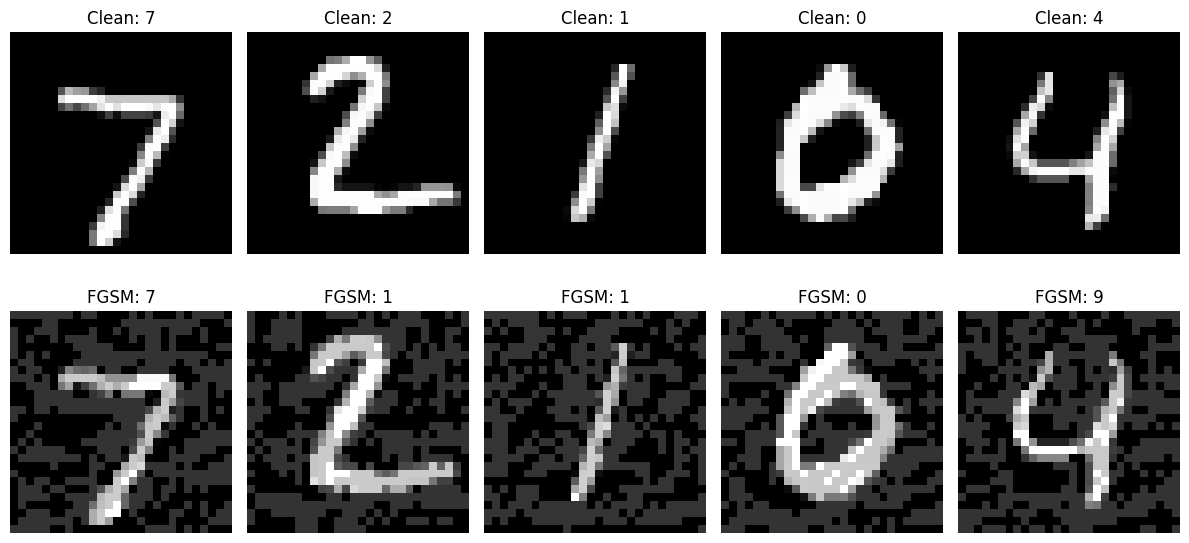

Mis-read digits saved : clean_vs_adversarial.png
Attack success (eps=0.20): FGSM 50.2 %, PGD 92.3 %


In [9]:
model.eval()
images, labels = next(iter(DataLoader(test_dataset, batch_size=5, shuffle=False)))
images.requires_grad = True
outputs = model(images)
loss = criterion(outputs, labels)
model.zero_grad()
loss.backward()
data_grad = images.grad.data
perturbed_images = fgsm_attack(images, 0.20, data_grad)

with torch.no_grad():
    clean_preds = torch.max(model(images), 1)[1]
    adv_preds = torch.max(model(perturbed_images), 1)[1]

fig, axes = plt.subplots(2, 5, figsize=(12, 6))
for i in range(5):
    axes[0, i].imshow(images[i].squeeze().detach().numpy(), cmap='gray')
    axes[0, i].set_title(f"Clean: {clean_preds[i].item()}")
    axes[0, i].axis('off')

    axes[1, i].imshow(perturbed_images[i].squeeze().detach().numpy(), cmap='gray')
    axes[1, i].set_title(f"FGSM: {adv_preds[i].item()}")
    axes[1, i].axis('off')

plt.tight_layout()
plt.savefig('clean_vs_adversarial.png')
plt.show()
print("Mis-read digits saved : clean_vs_adversarial.png")
print(f"Attack success (eps=0.20): FGSM {100 - fgsm_accs[3]:.1f} %, PGD {100 - pgd_accs[3]:.1f} %")

In [10]:
adv_model = BaselineCNN()
adv_optimizer = optim.Adam(adv_model.parameters(), lr=0.001)

adv_model.train()
for epoch in range(2):
    for images, labels in train_loader:
        images.requires_grad = True
        outputs = adv_model(images)
        loss = criterion(outputs, labels)
        adv_model.zero_grad()
        loss.backward()

        data_grad = images.grad.data
        perturbed_images = fgsm_attack(images, 0.20, data_grad)

        indices = torch.randperm(images.size(0))
        split = images.size(0) // 2
        mixed_images = torch.cat([images[indices[:split]], perturbed_images[indices[split:]]], dim=0).detach()
        mixed_labels = torch.cat([labels[indices[:split]], labels[indices[split:]]], dim=0)

        adv_optimizer.zero_grad()
        outputs_mixed = adv_model(mixed_images)
        loss_mixed = criterion(outputs_mixed, mixed_labels)
        loss_mixed.backward()
        adv_optimizer.step()

In [11]:
adv_clean = evaluate_attack(adv_model, device, test_loader, 0.0, 'clean')
adv_fgsm = evaluate_attack(adv_model, device, test_loader, 0.20, 'fgsm')
adv_pgd = evaluate_attack(adv_model, device, test_loader, 0.20, 'pgd')

print("MODEL CLEAN FGSM(0.20) PGD(0.20)")
print("----------------------------------------------------")
print(f"Baseline {clean_acc:.1f} % {fgsm_accs[3]:.1f} % {pgd_accs[3]:.1f} %")
print(f"Adversarially trained {adv_clean:.1f} % {adv_fgsm:.1f} % {adv_pgd:.1f} %")
print("----------------------------------------------------")

clean_diff = adv_clean - clean_acc
fgsm_diff = adv_fgsm - fgsm_accs[3]
pgd_diff = adv_pgd - pgd_accs[3]

print(f"Clean accuracy change : {clean_diff:+.1f} %")
print(f"FGSM robustness gain : {fgsm_diff:+.1f} % PGD gain : {pgd_diff:+.1f} %")

MODEL CLEAN FGSM(0.20) PGD(0.20)
----------------------------------------------------
Baseline 98.6 % 49.8 % 7.7 %
Adversarially trained 98.4 % 85.2 % 9.2 %
----------------------------------------------------
Clean accuracy change : -0.2 %
FGSM robustness gain : +35.4 % PGD gain : +1.5 %


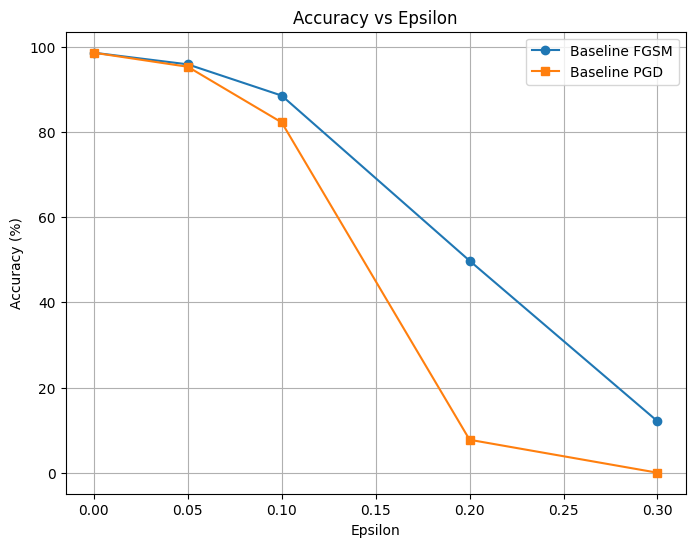

Plot saved : accuracy_vs_epsilon.png


In [12]:
plt.figure(figsize=(8, 6))
plt.plot(epsilons, fgsm_accs, 'o-', label='Baseline FGSM')
plt.plot(epsilons, pgd_accs, 's-', label='Baseline PGD')
plt.xlabel('Epsilon')
plt.ylabel('Accuracy (%)')
plt.title('Accuracy vs Epsilon')
plt.legend()
plt.grid(True)
plt.savefig('accuracy_vs_epsilon.png')
plt.show()
print("Plot saved : accuracy_vs_epsilon.png")